# HRIPCB — Exploratory Data Analysis
### `notebooks/00_data_exploration.ipynb` · pcb-aoi · Stage 0.4

This notebook is the first formal output of the **pcb-aoi** project: a PCB
Automated Optical Inspection (AOI) pipeline built on the **HRIPCB** dataset.

## 1. Dataset

**HRIPCB** (also distributed as *PCB_DATASET*) was released by the Open Lab on
Human–Robot Interaction, **Peking University**. It contains high-resolution
images of printed circuit boards onto which six common manufacturing defects
have been synthetically introduced and hand-annotated.

> **Reference:** Weibo Huang and Peng Wei, *"A PCB Dataset for Defects Detection
> and Classification"*, arXiv:1901.08204, 2019. (Open Lab on Human–Robot
> Interaction, Peking University.)

We use the **base set** only (`images/`, `Annotations/`, `PCB_USED/`); the
repository's pre-rotated augmentation set is intentionally skipped — augmentation
will be done dynamically at train time with `torchvision` instead.

### The six defect classes (英 / 中)

| # | class | 中文 | description |
|---|-------|------|-------------|
| 1 | `missing_hole` | 缺孔 | a drilled hole is absent |
| 2 | `mouse_bite` | 鼠咬 (邊緣缺口) | small semicircular nibble on a track edge |
| 3 | `open_circuit` | 斷路 | a conductive track is broken |
| 4 | `short` | 短路 | two tracks bridged by unwanted copper |
| 5 | `spur` | 毛刺 (凸尖) | a thin protrusion off a track |
| 6 | `spurious_copper` | 多餘銅 (殘銅) | stray copper where there should be none |

### Annotation format

Pascal-**VOC XML**, one file per image. Each `<object>` holds a class `<name>`
and an axis-aligned `<bndbox>` (`xmin, ymin, xmax, ymax`). All defects within a
given image share the same class (the dataset is organised one-defect-type per
image).

In [1]:
import sys
from pathlib import Path

# project root = parent of this notebook's folder
ROOT = Path.cwd().parent if (Path.cwd() / "00_data_exploration.ipynb").exists() else Path.cwd()
if not (ROOT / "src").exists():
    ROOT = Path(r"D:\ash-portfolio\pcb-aoi")
sys.path.insert(0, str(ROOT))

import matplotlib
matplotlib.use("Agg")          # figures are saved + embedded explicitly
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display

from src import eda
from src.hripcb import CLASSES, CLASS_ZH

DATA = ROOT / "data" / "HRIPCB"
FIG = ROOT / "results" / "figures"
print("project root:", ROOT)
print("data dir     :", DATA, "| exists:", DATA.exists())

project root: D:\ash-portfolio\pcb-aoi
data dir     : D:\ash-portfolio\pcb-aoi\data\HRIPCB | exists: True


In [2]:
anns = eda.load_dataset(DATA)
stats = eda.compute_stats(anns)
print(f"Parsed {stats['n_images']} annotated images, {stats['n_boxes']} defect boxes total.")

Parsed 693 annotated images, 2953 defect boxes total.


## 2. Data distribution

How balanced are the classes, how many defects appear per image, and how big are
they? These drive model choices downstream.

In [3]:
rows = [{"class": c, "中文": CLASS_ZH[c],
         "images": stats["img_per_class"].get(c, 0),
         "boxes": stats["box_per_class"].get(c, 0)} for c in CLASSES]
df_dist = pd.DataFrame(rows)
df_dist.loc["total"] = ["—", "—", df_dist["images"].sum(), df_dist["boxes"].sum()]
df_dist

,class,中文,images,boxes
0,missing_hole,缺孔,115,497
1,mouse_bite,鼠咬(缺口),115,492
2,open_circuit,斷路,116,482
3,short,短路,116,491
4,spur,毛刺(凸尖),115,488
5,spurious_copper,多餘銅(殘銅),116,503
total,—,—,693,2953


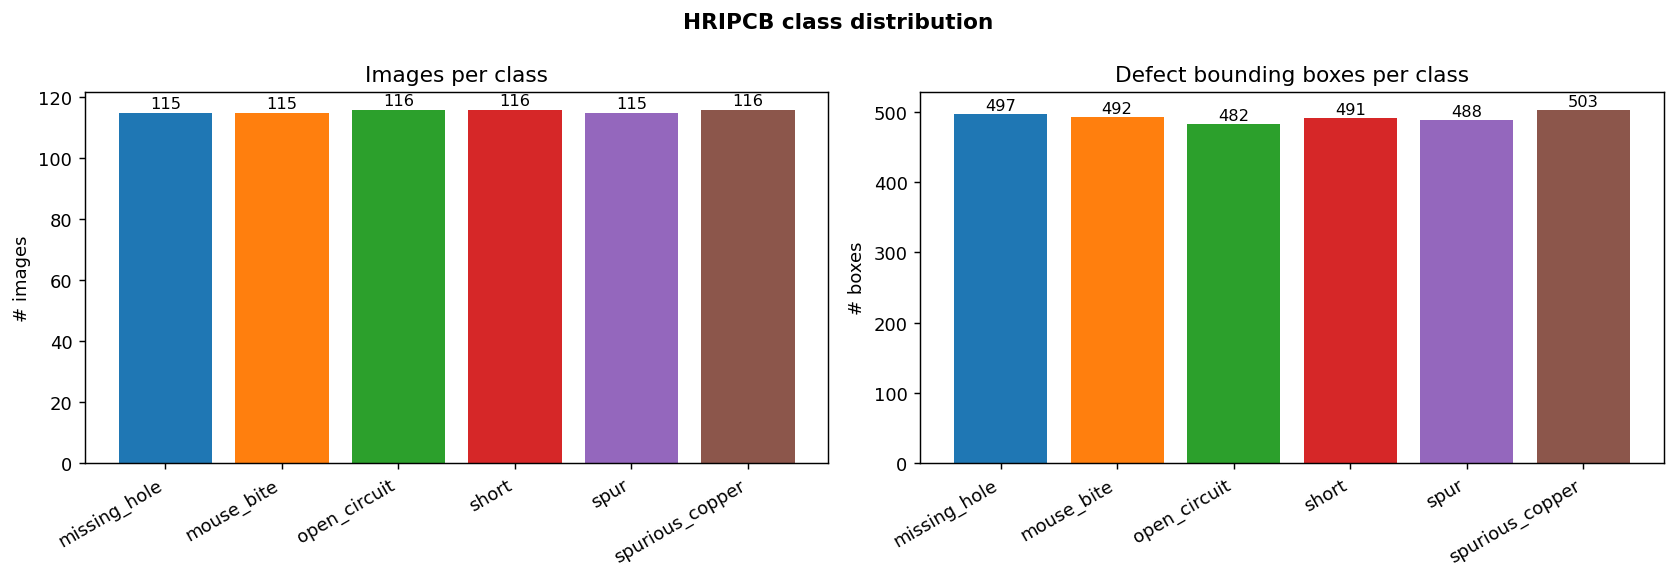

In [4]:
display(Image(filename=str(eda.plot_class_distribution(stats, FIG))))

boxes per image: min=1, max=6, mean=4.26


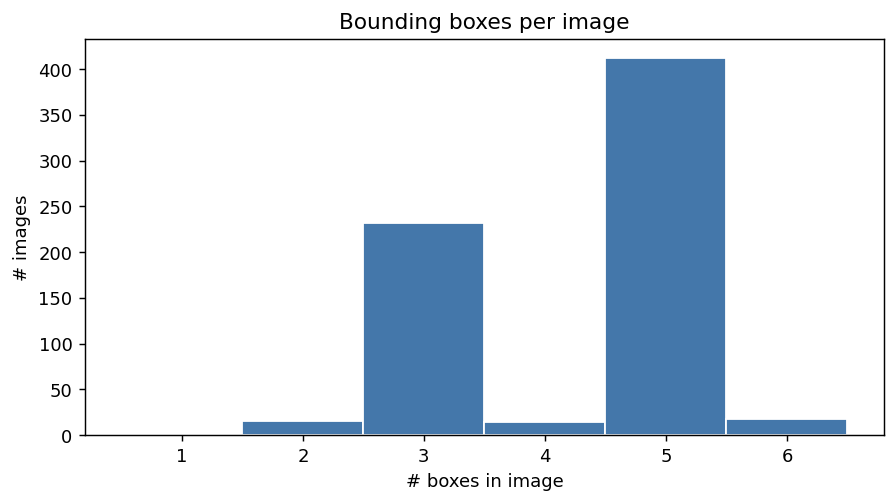

In [5]:
bpi = stats["boxes_per_image"]
print(f"boxes per image: min={min(bpi)}, max={max(bpi)}, mean={sum(bpi)/len(bpi):.2f}")
display(Image(filename=str(eda.plot_boxes_per_image_hist(stats, FIG))))

In [6]:
# image resolutions present (one per underlying PCB template)
sz = pd.DataFrame(
    [{"resolution": f"{w}x{h}", "count": c} for (w, h), c in stats["img_sizes"].items()]
).sort_values("count", ascending=False).reset_index(drop=True)
print(f"{len(sz)} distinct image resolutions")
sz

10 distinct image resolutions


,resolution,count
0,3034x1586,120
1,3056x2464,120
2,2868x2316,61
3,2544x2156,60
4,2904x1921,60
5,2759x2154,60
6,2775x2159,60
7,2282x2248,60
8,2529x2530,60
9,2240x2016,32


In [7]:
# defect bounding-box size per class (pixels^2)
import statistics as st
area_rows = []
for c in CLASSES:
    a = stats["areas"][c]
    area_rows.append({"class": c, "n_boxes": len(a),
                      "area_min": min(a), "area_median": int(st.median(a)),
                      "area_max": max(a),
                      "w_median": int(st.median(stats["box_w"][c])),
                      "h_median": int(st.median(stats["box_h"][c]))})
df_area = pd.DataFrame(area_rows)
df_area

,class,n_boxes,area_min,area_median,area_max,w_median,h_median
0,missing_hole,497,1681,4092,19460,64,64
1,mouse_bite,492,800,3723,9516,61,62
2,open_circuit,482,625,2434,8924,51,49
3,short,491,1254,6084,37268,82,74
4,spur,488,990,4893,15708,72,64
5,spurious_copper,503,1400,5198,16241,67,73


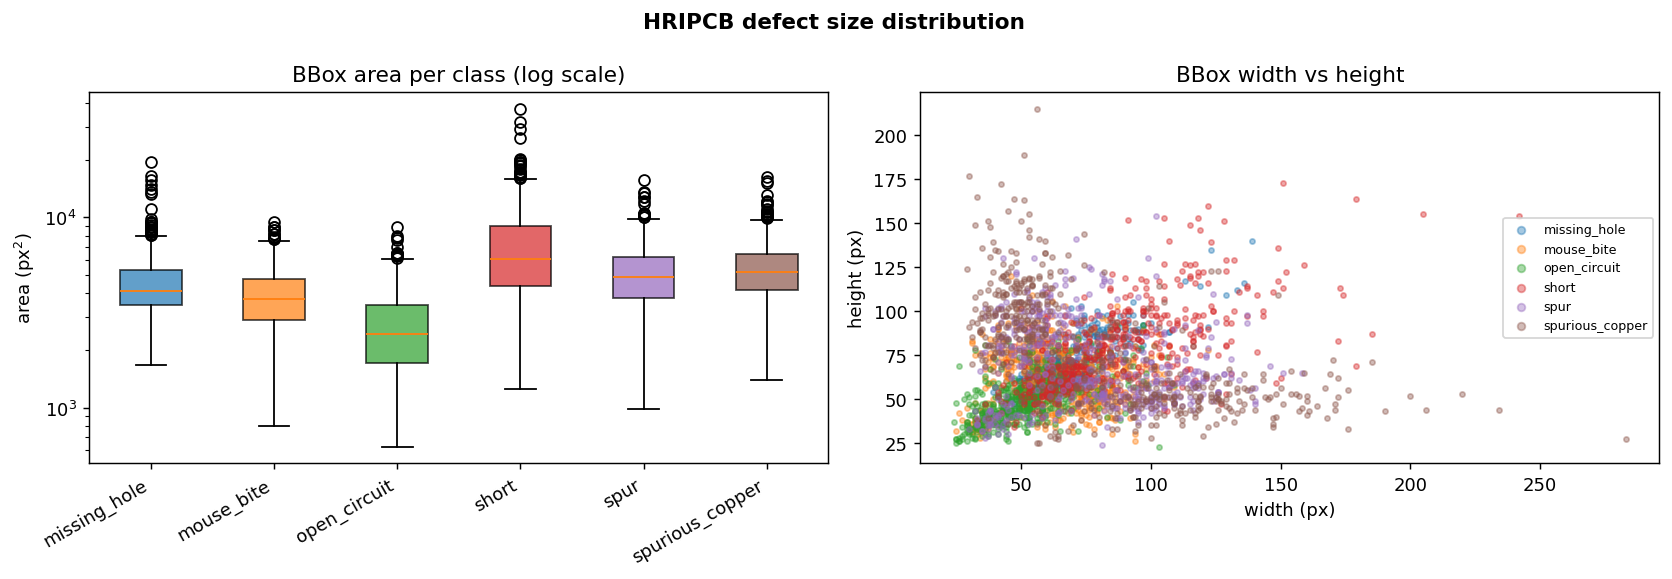

In [8]:
display(Image(filename=str(eda.plot_bbox_size_distribution(stats, FIG))))

## 3. Sample defects

Two representative images per class with ground-truth boxes drawn in red. Defects
are *small* relative to these multi-megapixel boards — note how the boxes occupy
a tiny fraction of each image.

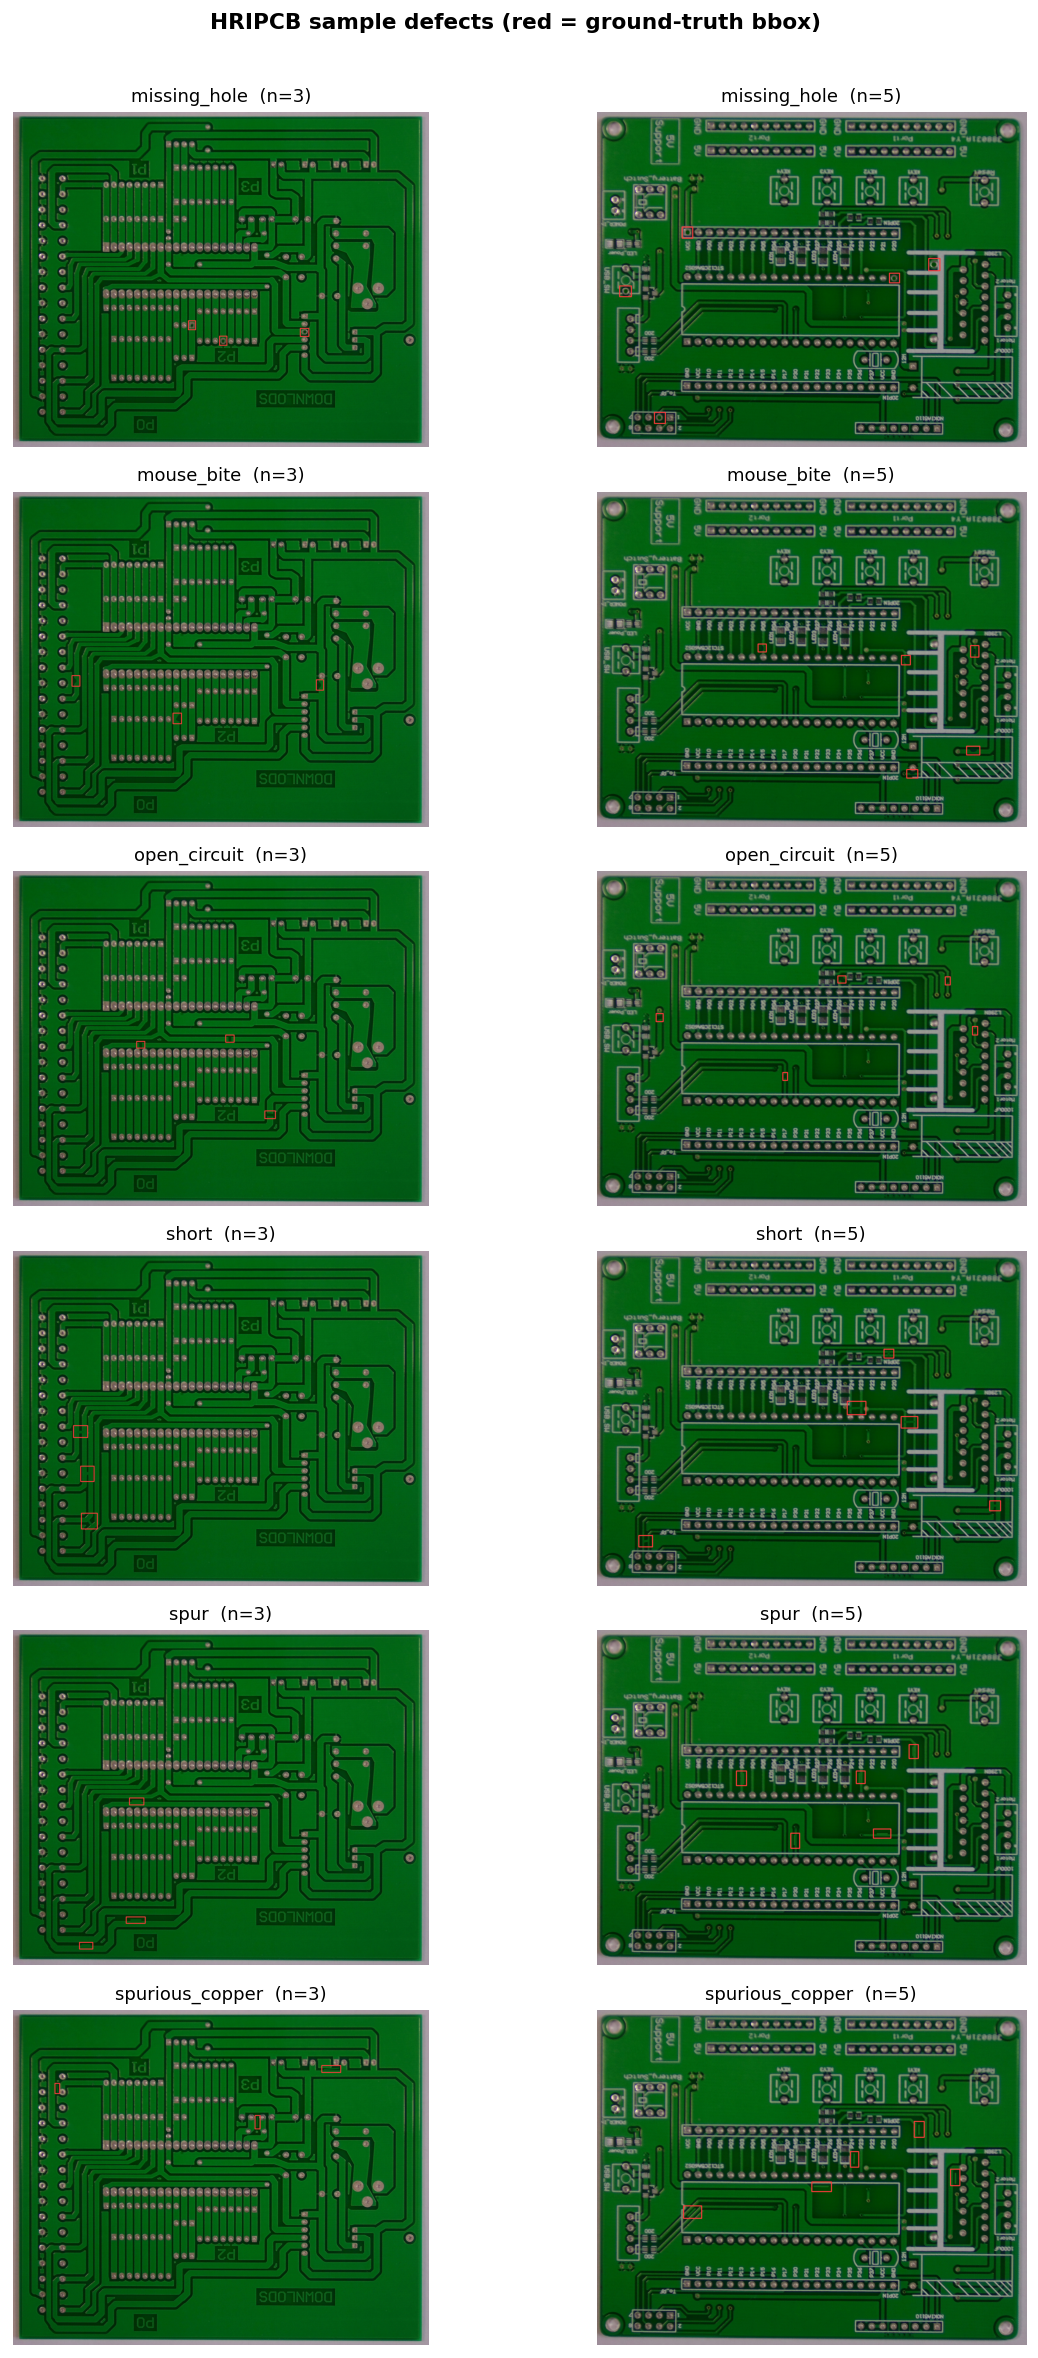

In [9]:
display(Image(filename=str(eda.plot_sample_grid(anns, DATA, FIG, per_class=2))))

## 4. Defect-free templates (`PCB_USED/`)

Ten clean reference boards. Defective images are derived from these, so each
template anchors a family of defect images — useful for a **reference-vs-test
difference** baseline in Stage 1.

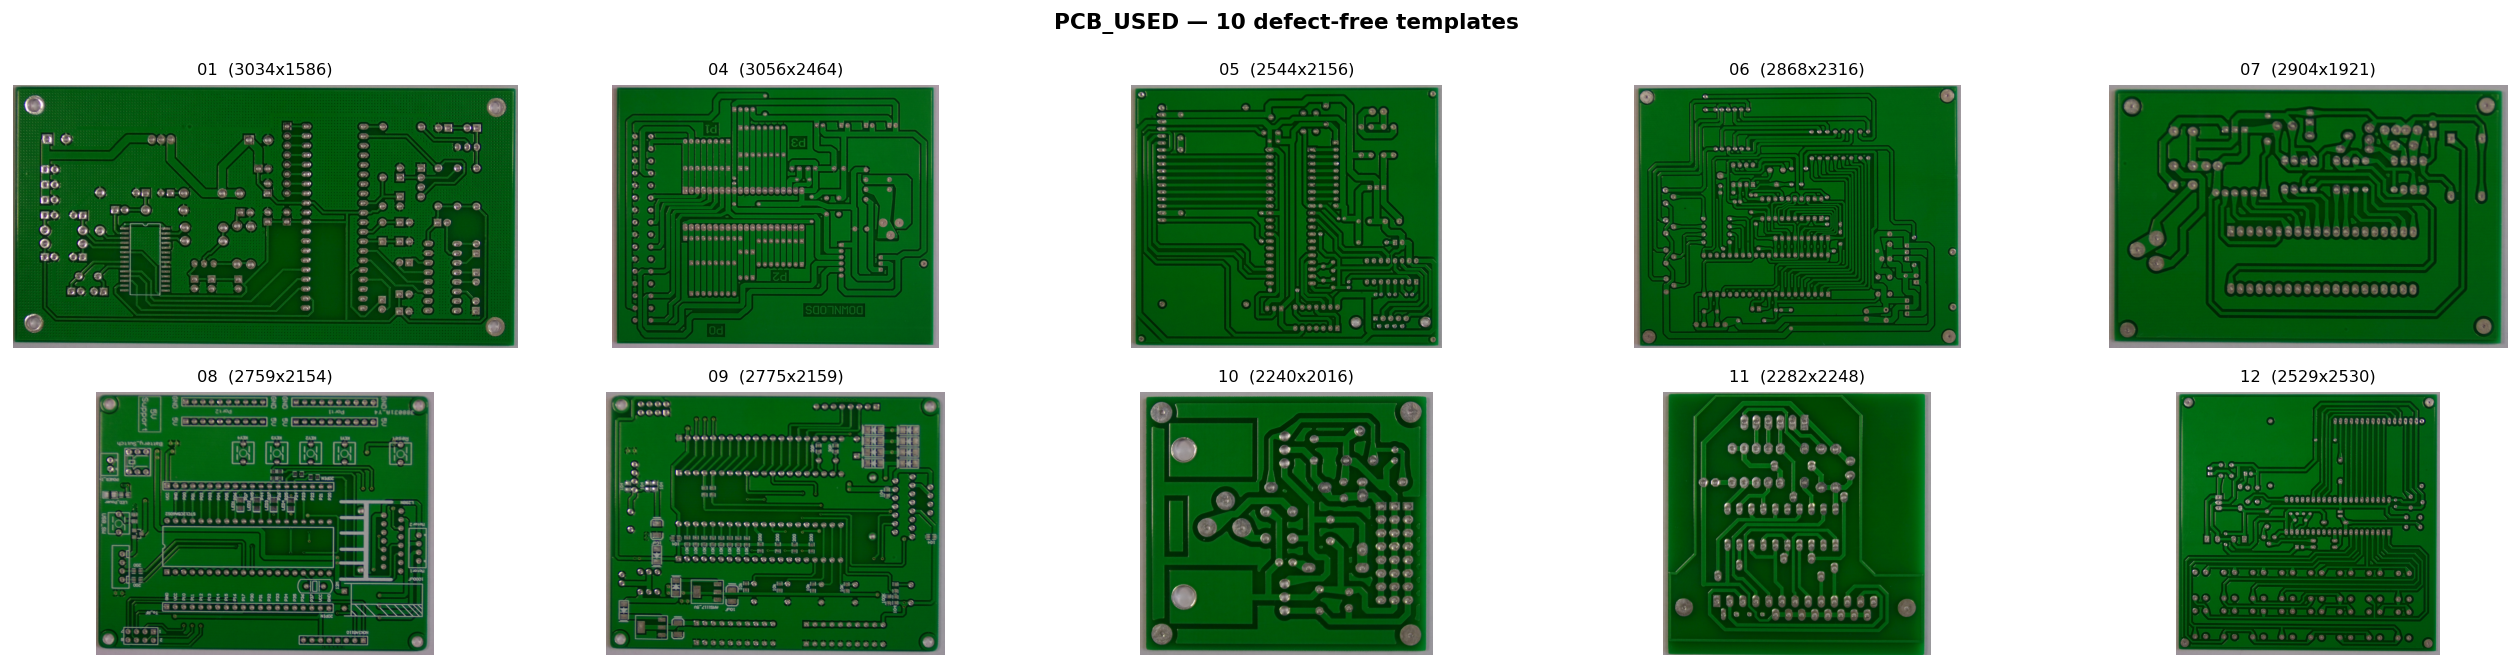

In [10]:
display(Image(filename=str(eda.plot_templates(DATA, FIG))))

In [11]:
# which defect classes were generated from each template id (parsed from filenames)
from collections import defaultdict
tmpl_map = defaultdict(set)
for a in anns:
    tid = a.filename.split("_")[0]          # e.g. '01' in 01_missing_hole_01.jpg
    if a.objects:
        tmpl_map[tid].add(a.objects[0].name)
pd.DataFrame(
    [{"template": t, "defect classes": ", ".join(sorted(tmpl_map[t]))}
     for t in sorted(tmpl_map)]
)

,template,defect classes
0,01,"missing_hole, mouse_bite, open_circuit, short,..."
1,04,"missing_hole, mouse_bite, open_circuit, short,..."
2,05,"missing_hole, mouse_bite, open_circuit, short,..."
3,06,"missing_hole, mouse_bite, open_circuit, short,..."
4,07,"missing_hole, mouse_bite, open_circuit, short,..."
5,08,"missing_hole, mouse_bite, open_circuit, short,..."
6,09,"missing_hole, mouse_bite, open_circuit, short,..."
7,10,"missing_hole, mouse_bite, open_circuit, short,..."
8,11,"missing_hole, mouse_bite, open_circuit, short,..."
9,12,"missing_hole, mouse_bite, open_circuit, short,..."


## 5. Data-quality checks

Scan every image + annotation for problems that would bite us later: unreadable
files, XML/image size mismatches, out-of-bounds or degenerate boxes, and
duplicate images (by content hash).

In [12]:
issues = eda.quality_checks(anns, DATA)
pd.DataFrame([issues["summary"]]).T.rename(columns={0: "count"})

,count
unreadable_images,0
size_mismatch,0
oob_boxes,0
degenerate_boxes,0
duplicate_images,0
missing_image_file,0


## Findings

See **`results/eda_summary.md`** for the written summary and its implications for
the Stage 1 (classical-CV) baseline.